## 1. Install required libraries

In [1]:
%pip install -q kagglehub torch torchvision scikit-learn seaborn matplotlib pillow pandas ultralytics

## 2. Import libraries and check GPU

In [ ]:
import os, random, time, copy, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import datasets, transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Using device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
Using device: cuda
GPU: Tesla T4


## 3. Download the Kaggle dataset

In [3]:
import kagglehub

DATASET_SLUG = "rajdalsaniya/pothole-detection-dataset"
dataset_path = kagglehub.dataset_download(DATASET_SLUG)
DATASET_PATH = Path(dataset_path)

print("Dataset downloaded to:", DATASET_PATH)

100%|██████████| 235M/235M [00:01<00:00, 133MB/s]

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/rajdalsaniya/pothole-detection-dataset/versions/1


## 4. Inspect the downloaded folder structure

In [4]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for root, dirs, files in os.walk(DATASET_PATH):
    level = len(Path(root).relative_to(DATASET_PATH).parts)
    if level <= 3:
        print("  " * level + Path(root).name + "/")
        for filename in files[:6]:
            print("  " * (level + 1) + filename)

1/
  README.roboflow.txt
  data.yaml
  valid/
    images/
      552_jpg.rf.b38e499d872c1ed47b181022b8b1ee9d.jpg
      595_jpg.rf.bdce8cee8f9d1283851517aa8de79a30.jpg
      9_jpg.rf.0fb30cfe880b3e1510466e6c20575ba3.jpg
      12_jpg.rf.b7c796cd5cf305af4937c9b3d38a4434.jpg
      596_jpg.rf.897113e5a3ee905d3afad5340386aa0b.jpg
      553_jpg.rf.a5586080c55d3f70e84a9f6e4264acc8.jpg
    labels/
      8_jpg.rf.1c96f62d936a4c9f0d6a49bce97bf010.txt
      55_jpg.rf.400e2e551363b197413591d43b898663.txt
      12_jpg.rf.c1509424ec0b2f24bd396d890752db7a.txt
      8_jpg.rf.88508100d861f1957cb2b3b231ac9ef1.txt
      9_jpg.rf.0fb30cfe880b3e1510466e6c20575ba3.txt
      595_jpg.rf.bdce8cee8f9d1283851517aa8de79a30.txt
  train/
    images/
      297_jpg.rf.0d64f584e7513909b2aa29055379f599.jpg
      317_jpg.rf.50d6506b23debb58cf14d1f979a6886c.jpg
      617_jpg.rf.2974dd0a707627439c559599d061546a.jpg
      490_jpg.rf.1d46f70c0d9b0c6671987986d9a19454.jpg
      174_jpg.rf.633b8e82d6a8969f3876f9f1231b91bf.jpg
  

## 5. Detect the image-class folders

The following cell looks for folders containing class subfolders (for example, `Pothole/` and `Normal/`). It supports datasets that already have `train`, `valid`/`val`, and `test` folders, as well as datasets that need to be split automatically.

If the Kaggle dataset contains only one class or only bounding-box annotation files, image classification cannot create a valid pothole-vs-normal classifier from it without suitable negative images and image-level labels. The notebook will stop with a clear message rather than invent labels.

In [5]:
def image_count(folder):
    folder = Path(folder)
    return sum(1 for p in folder.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)

def has_class_subfolders(folder, min_classes=2):
    folder = Path(folder)
    if not folder.exists():
        return False
    class_dirs = [p for p in folder.iterdir() if p.is_dir() and image_count(p) > 0]
    return len(class_dirs) >= min_classes

split_names = {"train", "training", "val", "valid", "validation", "test", "testing"}
split_dirs = {}
for root, dirs, files in os.walk(DATASET_PATH):
    root_path = Path(root)
    name = root_path.name.lower()
    if name in split_names and has_class_subfolders(root_path):
        key = "train" if name in {"train", "training"} else (
            "val" if name in {"val", "valid", "validation"} else "test"
        )
        split_dirs.setdefault(key, root_path)

print("Detected split folders:")
for k, v in split_dirs.items():
    print(k, "->", v)

if "train" in split_dirs:
    train_dir = split_dirs["train"]
    val_dir = split_dirs.get("val")
    test_dir = split_dirs.get("test")
    CLASS_ROOT = None
else:
    candidates = []
    for root, dirs, files in os.walk(DATASET_PATH):
        p = Path(root)
        if p.name.lower() in split_names:
            continue
        if has_class_subfolders(p):
            candidates.append(p)
    if not candidates:
        raise RuntimeError(
            "Could not find at least two image class folders. Inspect the printed folder tree. "
            "This dataset may be detection-only (images plus bounding-box labels) or may need manual folder selection."
        )
    CLASS_ROOT = max(candidates, key=lambda p: image_count(p))
    train_dir = val_dir = test_dir = None
    print("Using class-folder root:", CLASS_ROOT)

if train_dir is not None:
    class_names = sorted([p.name for p in train_dir.iterdir() if p.is_dir() and image_count(p) > 0])
else:
    class_names = sorted([p.name for p in CLASS_ROOT.iterdir() if p.is_dir() and image_count(p) > 0])

print("Detected classes:", class_names)
if len(class_names) < 2:
    raise RuntimeError("At least two classes are required for pothole-vs-normal classification.")

Detected split folders:
Using class-folder root: /root/.cache/kagglehub/datasets/rajdalsaniya/pothole-detection-dataset/versions/1
Detected classes: ['train', 'valid']


## 6. Count images in each class

In [6]:
def count_images_per_class(folder):
    result = {}
    for class_dir in sorted(Path(folder).iterdir()):
        if class_dir.is_dir():
            result[class_dir.name] = image_count(class_dir)
    return result

if train_dir is not None:
    train_counts = count_images_per_class(train_dir)
else:
    train_counts = count_images_per_class(CLASS_ROOT)

display(pd.DataFrame({"Class": list(train_counts.keys()), "Images": list(train_counts.values())}))

,Class,Images
0,train,2067
1,valid,16


## 7. Visualize class distribution and sample images

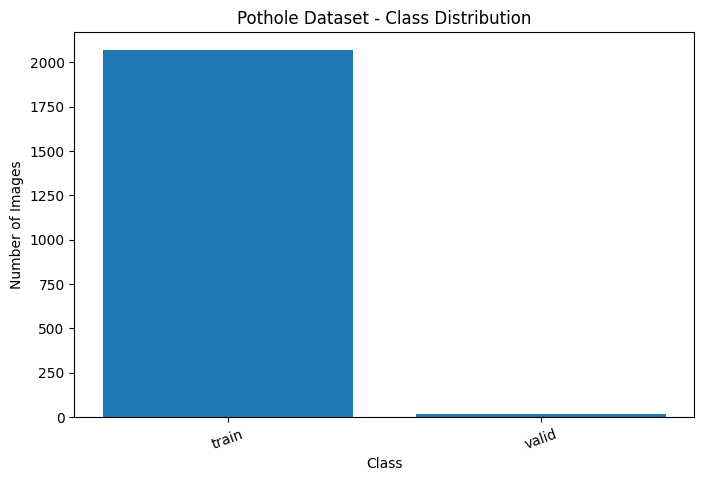

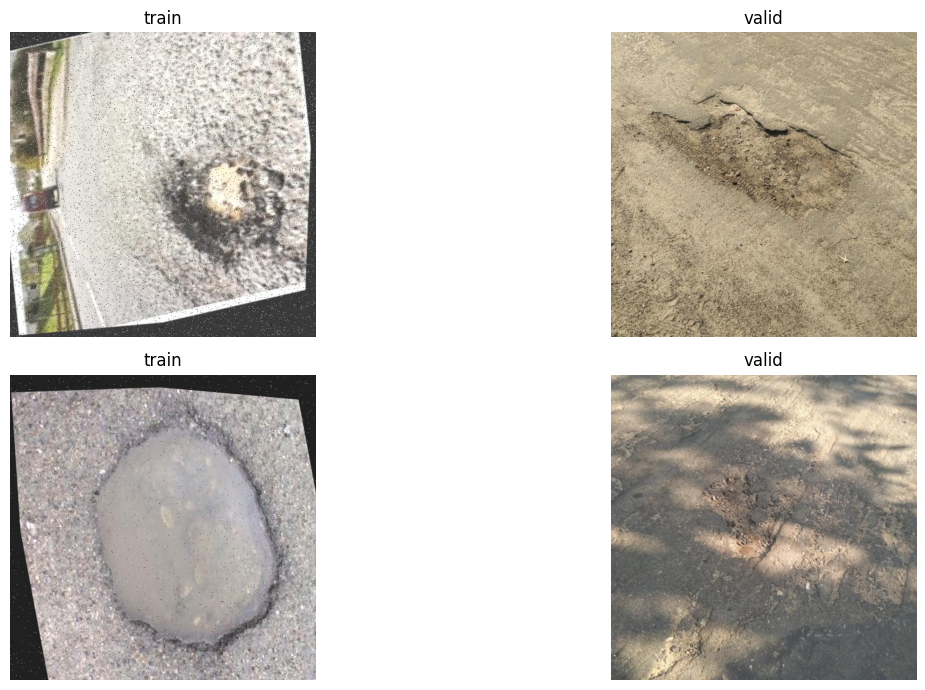

In [7]:
plt.figure(figsize=(8, 5))
plt.bar(train_counts.keys(), train_counts.values())
plt.title("Pothole Dataset - Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=20)
plt.show()

sample_root = train_dir if train_dir is not None else CLASS_ROOT
fig, axes = plt.subplots(2, min(4, len(class_names)), figsize=(15, 7))
axes = np.array(axes).reshape(2, -1)
for col, cls in enumerate(class_names[:4]):
    files = [p for p in (sample_root / cls).rglob("*") if p.suffix.lower() in IMAGE_EXTENSIONS]
    for row in range(2):
        ax = axes[row, col]
        if row < len(files):
            img = Image.open(files[row]).convert("RGB")
            ax.imshow(img)
            ax.set_title(cls)
        ax.axis("off")
plt.tight_layout()
plt.show()

## 8. Prepare training, validation and test datasets

In [8]:
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

if train_dir is not None:
    train_dataset = datasets.ImageFolder(str(train_dir), transform=train_transform)
    val_dataset = datasets.ImageFolder(str(val_dir), transform=eval_transform) if val_dir else None
    test_dataset = datasets.ImageFolder(str(test_dir), transform=eval_transform) if test_dir else None

    if val_dataset is None:
        print("No validation split found. Creating validation and test subsets from training data.")
        full_train_eval = datasets.ImageFolder(str(train_dir), transform=eval_transform)
        indices = np.arange(len(full_train_eval))
        train_idx, temp_idx = train_test_split(
            indices, test_size=0.30, random_state=SEED,
            stratify=full_train_eval.targets
        )
        val_idx, test_idx = train_test_split(
            temp_idx, test_size=0.50, random_state=SEED,
            stratify=np.array(full_train_eval.targets)[temp_idx]
        )
        train_dataset = Subset(train_dataset, train_idx)
        val_dataset = Subset(full_train_eval, val_idx)
        test_dataset = Subset(full_train_eval, test_idx)
else:
    full_train = datasets.ImageFolder(str(CLASS_ROOT), transform=train_transform)
    full_eval = datasets.ImageFolder(str(CLASS_ROOT), transform=eval_transform)
    indices = np.arange(len(full_train))
    train_idx, temp_idx = train_test_split(
        indices, test_size=0.30, random_state=SEED, stratify=full_train.targets
    )
    val_idx, test_idx = train_test_split(
        temp_idx, test_size=0.50, random_state=SEED,
        stratify=np.array(full_train.targets)[temp_idx]
    )
    train_dataset = Subset(full_train, train_idx)
    val_dataset = Subset(full_eval, val_idx)
    test_dataset = Subset(full_eval, test_idx)

# Confirm class mapping is consistent across all splits.
base_dataset = train_dataset.dataset if isinstance(train_dataset, Subset) else train_dataset
class_names = base_dataset.classes
num_classes = len(class_names)
print("Classes:", class_names)
print("Number of classes:", num_classes)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset) if test_dataset else 0)

Classes: ['train', 'valid']
Number of classes: 2
Training images: 1458
Validation images: 312
Test images: 313


## 9. Create DataLoaders and inspect a batch

In [9]:
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available()) if test_dataset else None

images, labels = next(iter(train_loader))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])


## 10. Define training and evaluation functions

In [10]:
def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss, total_correct, total = 0.0, 0, 0
    all_labels, all_preds = [], []

    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            if training:
                optimizer.zero_grad()
            logits = model(x)
            loss = criterion(logits, y)
            if training:
                loss.backward()
                optimizer.step()

            preds = logits.argmax(dim=1)
            total_loss += loss.item() * x.size(0)
            total_correct += (preds == y).sum().item()
            total += x.size(0)
            all_labels.extend(y.detach().cpu().numpy())
            all_preds.extend(preds.detach().cpu().numpy())

    return total_loss / max(total, 1), total_correct / max(total, 1), all_labels, all_preds


def train_model(model, model_name, epochs=10, learning_rate=1e-4):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)

    history = {"train_loss": [], "train_accuracy": [], "val_loss": [], "val_accuracy": []}
    best_acc = -1
    best_weights = copy.deepcopy(model.state_dict())
    patience, wait = 4, 0
    start = time.time()

    for epoch in range(epochs):
        tr_loss, tr_acc, _, _ = run_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc, _, _ = run_epoch(model, val_loader, criterion)
        scheduler.step(va_acc)

        history["train_loss"].append(tr_loss)
        history["train_accuracy"].append(tr_acc)
        history["val_loss"].append(va_loss)
        history["val_accuracy"].append(va_acc)

        print(f"{model_name} | Epoch {epoch+1:02d}/{epochs} "
              f"| Train Acc: {tr_acc*100:.2f}% | Val Acc: {va_acc*100:.2f}% "
              f"| Train Loss: {tr_loss:.4f} | Val Loss: {va_loss:.4f}")

        if va_acc > best_acc:
            best_acc = va_acc
            best_weights = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print("Early stopping.")
                break

    model.load_state_dict(best_weights)
    elapsed = time.time() - start
    return model, history, best_acc, elapsed

## 11. Train EfficientNet-B0 (transfer learning)

In [11]:
weights = models.EfficientNet_B0_Weights.DEFAULT
efficientnet = models.efficientnet_b0(weights=weights)
efficientnet.classifier[1] = nn.Linear(efficientnet.classifier[1].in_features, num_classes)

EPOCHS = 12
efficientnet, efficientnet_history, efficientnet_best_val, efficientnet_time = train_model(
    efficientnet, "EfficientNet-B0", epochs=EPOCHS, learning_rate=1e-4
)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 112MB/s]


EfficientNet-B0 | Epoch 01/12 | Train Acc: 94.79% | Val Acc: 99.36% | Train Loss: 0.3151 | Val Loss: 0.0609
EfficientNet-B0 | Epoch 02/12 | Train Acc: 99.25% | Val Acc: 99.36% | Train Loss: 0.0600 | Val Loss: 0.0251
EfficientNet-B0 | Epoch 03/12 | Train Acc: 99.52% | Val Acc: 100.00% | Train Loss: 0.0254 | Val Loss: 0.0119
EfficientNet-B0 | Epoch 04/12 | Train Acc: 99.93% | Val Acc: 100.00% | Train Loss: 0.0125 | Val Loss: 0.0069
EfficientNet-B0 | Epoch 05/12 | Train Acc: 99.86% | Val Acc: 100.00% | Train Loss: 0.0084 | Val Loss: 0.0059
EfficientNet-B0 | Epoch 06/12 | Train Acc: 100.00% | Val Acc: 100.00% | Train Loss: 0.0059 | Val Loss: 0.0041
EfficientNet-B0 | Epoch 07/12 | Train Acc: 100.00% | Val Acc: 100.00% | Train Loss: 0.0041 | Val Loss: 0.0036
Early stopping.


## 12. Plot EfficientNet-B0 training and validation accuracy/loss

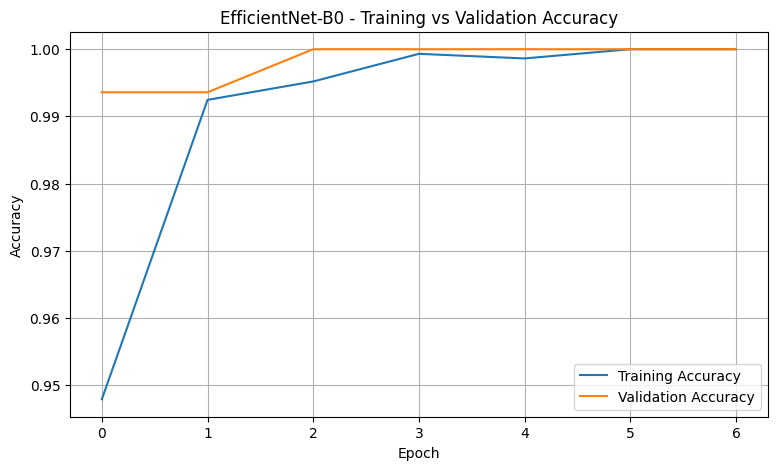

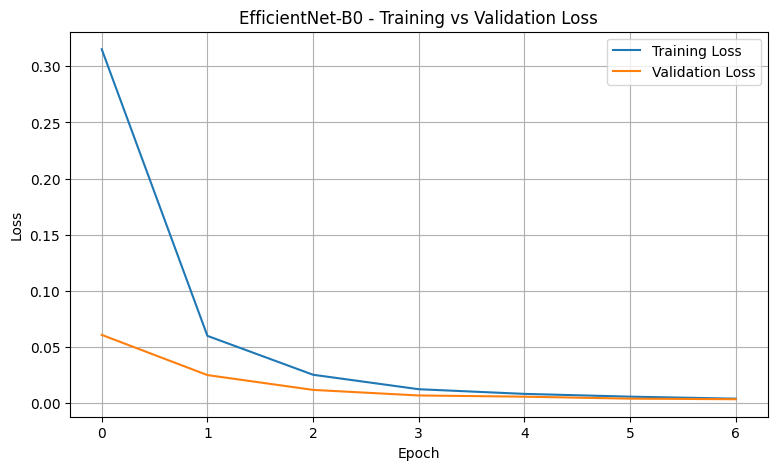

In [12]:
plt.figure(figsize=(9, 5))
plt.plot(efficientnet_history["train_accuracy"], label="Training Accuracy")
plt.plot(efficientnet_history["val_accuracy"], label="Validation Accuracy")
plt.title("EfficientNet-B0 - Training vs Validation Accuracy")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend(); plt.grid(); plt.show()

plt.figure(figsize=(9, 5))
plt.plot(efficientnet_history["train_loss"], label="Training Loss")
plt.plot(efficientnet_history["val_loss"], label="Validation Loss")
plt.title("EfficientNet-B0 - Training vs Validation Loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.grid(); plt.show()

## 13. Define and train a Simple CNN

In [13]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.35), nn.Linear(256, num_classes))

    def forward(self, x):
        return self.classifier(self.features(x))

simple_cnn = SimpleCNN(num_classes)
simple_cnn, simple_history, simple_best_val, simple_time = train_model(
    simple_cnn, "Simple CNN", epochs=10, learning_rate=5e-4
)

Simple CNN | Epoch 01/10 | Train Acc: 92.94% | Val Acc: 99.36% | Train Loss: 0.2177 | Val Loss: 0.0482
Simple CNN | Epoch 02/10 | Train Acc: 99.25% | Val Acc: 99.36% | Train Loss: 0.0526 | Val Loss: 0.0426
Simple CNN | Epoch 03/10 | Train Acc: 99.25% | Val Acc: 99.36% | Train Loss: 0.0458 | Val Loss: 0.0295
Simple CNN | Epoch 04/10 | Train Acc: 99.25% | Val Acc: 99.36% | Train Loss: 0.0424 | Val Loss: 0.0321
Simple CNN | Epoch 05/10 | Train Acc: 99.25% | Val Acc: 99.36% | Train Loss: 0.0417 | Val Loss: 0.0289
Early stopping.


## 14. Train ResNet18

In [14]:
resnet18 = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
resnet18.fc = nn.Linear(resnet18.fc.in_features, num_classes)
resnet18, resnet_history, resnet_best_val, resnet_time = train_model(
    resnet18, "ResNet18", epochs=10, learning_rate=1e-4
)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 169MB/s]


ResNet18 | Epoch 01/10 | Train Acc: 88.00% | Val Acc: 99.36% | Train Loss: 0.2774 | Val Loss: 0.0602
ResNet18 | Epoch 02/10 | Train Acc: 99.59% | Val Acc: 99.68% | Train Loss: 0.0247 | Val Loss: 0.0145
ResNet18 | Epoch 03/10 | Train Acc: 99.73% | Val Acc: 100.00% | Train Loss: 0.0154 | Val Loss: 0.0065
ResNet18 | Epoch 04/10 | Train Acc: 99.93% | Val Acc: 100.00% | Train Loss: 0.0082 | Val Loss: 0.0070
ResNet18 | Epoch 05/10 | Train Acc: 100.00% | Val Acc: 100.00% | Train Loss: 0.0045 | Val Loss: 0.0044
ResNet18 | Epoch 06/10 | Train Acc: 100.00% | Val Acc: 100.00% | Train Loss: 0.0028 | Val Loss: 0.0031
ResNet18 | Epoch 07/10 | Train Acc: 100.00% | Val Acc: 100.00% | Train Loss: 0.0024 | Val Loss: 0.0028
Early stopping.


## 15. Evaluate models on the held-out test set

Evaluation split: Test

EfficientNet-B0 Test Accuracy: 99.04%
              precision    recall  f1-score   support

       train       0.99      1.00      1.00       310
       valid       0.00      0.00      0.00         3

    accuracy                           0.99       313
   macro avg       0.50      0.50      0.50       313
weighted avg       0.98      0.99      0.99       313



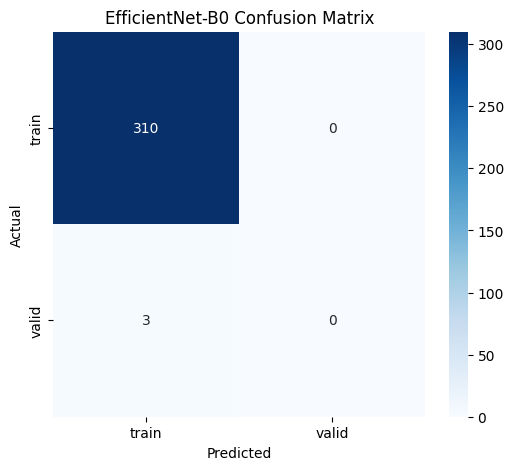


Simple CNN Test Accuracy: 99.04%
              precision    recall  f1-score   support

       train       0.99      1.00      1.00       310
       valid       0.00      0.00      0.00         3

    accuracy                           0.99       313
   macro avg       0.50      0.50      0.50       313
weighted avg       0.98      0.99      0.99       313



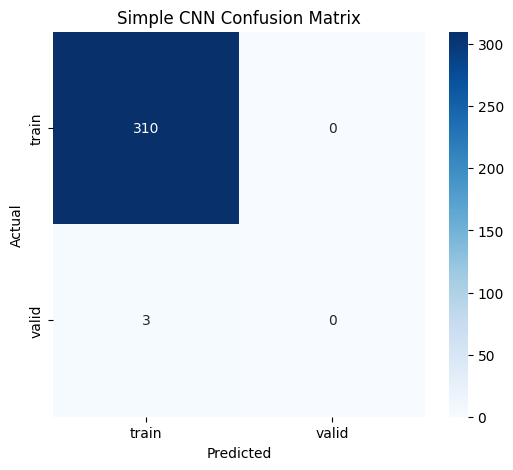


ResNet18 Test Accuracy: 99.36%
              precision    recall  f1-score   support

       train       0.99      1.00      1.00       310
       valid       1.00      0.33      0.50         3

    accuracy                           0.99       313
   macro avg       1.00      0.67      0.75       313
weighted avg       0.99      0.99      0.99       313



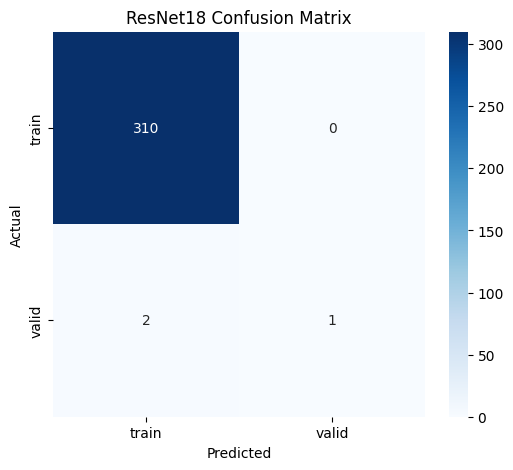

In [15]:
evaluation_loader = test_loader if test_loader is not None else val_loader
evaluation_name = "Test" if test_loader is not None else "Validation (no separate test split)"
print("Evaluation split:", evaluation_name)

def evaluate_model(model, model_name):
    criterion = nn.CrossEntropyLoss()
    loss, acc, y_true, y_pred = run_epoch(model, evaluation_loader, criterion)
    precision = precision_score(y_true, y_pred, average="weighted", zero_division=0)
    recall = recall_score(y_true, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)
    print(f"\n{model_name} {evaluation_name} Accuracy: {acc*100:.2f}%")
    print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title(f"{model_name} Confusion Matrix")
    plt.show()
    return {"Model": model_name, "Accuracy": acc, "Precision": precision,
            "Recall": recall, "F1-score": f1, "Loss": loss}, (y_true, y_pred)

eff_metrics, eff_predictions = evaluate_model(efficientnet, "EfficientNet-B0")
cnn_metrics, cnn_predictions = evaluate_model(simple_cnn, "Simple CNN")
res_metrics, res_predictions = evaluate_model(resnet18, "ResNet18")

## 16. Compare all trained models

,Model,Accuracy,Precision,Recall,F1-score,Loss
2,ResNet18,0.9936,0.9937,0.9936,0.9920,0.0325
0,EfficientNet-B0,0.9904,0.9809,0.9904,0.9856,0.0474
1,Simple CNN,0.9904,0.9809,0.9904,0.9856,0.0626


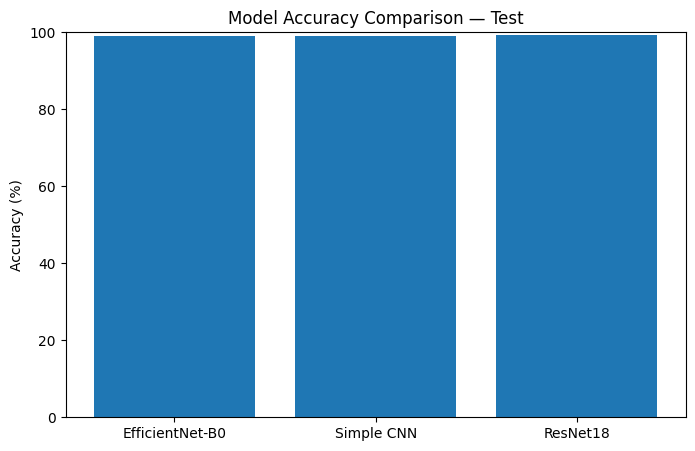

In [16]:
comparison_df = pd.DataFrame([eff_metrics, cnn_metrics, res_metrics])
display(comparison_df.sort_values("Accuracy", ascending=False).style.format({
    "Accuracy": "{:.4f}", "Precision": "{:.4f}", "Recall": "{:.4f}",
    "F1-score": "{:.4f}", "Loss": "{:.4f}"
}))

plt.figure(figsize=(8, 5))
plt.bar(comparison_df["Model"], comparison_df["Accuracy"] * 100)
plt.ylabel("Accuracy (%)")
plt.title(f"Model Accuracy Comparison — {evaluation_name}")
plt.ylim(0, 100)
plt.show()

## 17. Save the best-performing model

In [17]:
models_by_name = {
    "EfficientNet-B0": (efficientnet, efficientnet_best_val),
    "Simple CNN": (simple_cnn, simple_best_val),
    "ResNet18": (resnet18, resnet_best_val)
}
best_model_name = max(models_by_name, key=lambda k: models_by_name[k][1])
best_model = models_by_name[best_model_name][0]

torch.save({
    "model_name": best_model_name,
    "model_state_dict": best_model.state_dict(),
    "class_names": class_names,
    "image_size": IMG_SIZE
}, "/content/best_pothole_classifier.pth")

print("Best model based on validation accuracy:", best_model_name)
print("Saved to /content/best_pothole_classifier.pth")

Best model based on validation accuracy: EfficientNet-B0
Saved to /content/best_pothole_classifier.pth


## 18. Predict a new road image

Saving Screenshot 2026-11-04 160217.png to Screenshot 2026-11-04 160217.png
Uploaded: Screenshot 2026-11-04 160217.png
Predicted class: train
Confidence: 96.37%


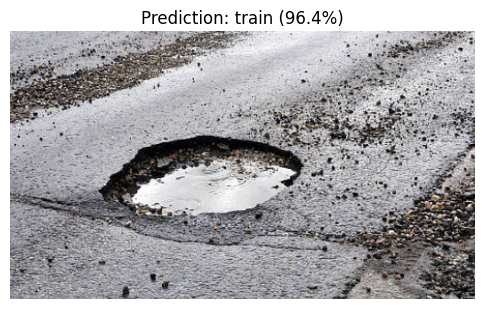


Class probabilities:
train: 96.37%
valid: 3.63%


In [18]:
from google.colab import files

uploaded = files.upload()
image_path = next(iter(uploaded))
print("Uploaded:", image_path)

best_model.eval()
image = Image.open(image_path).convert("RGB")
input_tensor = eval_transform(image).unsqueeze(0).to(device)

with torch.no_grad():
    logits = best_model(input_tensor)
    probabilities = torch.softmax(logits, dim=1)[0].cpu().numpy()

predicted_index = int(np.argmax(probabilities))
print("Predicted class:", class_names[predicted_index])
print(f"Confidence: {probabilities[predicted_index]*100:.2f}%")

plt.figure(figsize=(6, 5))
plt.imshow(image)
plt.title(f"Prediction: {class_names[predicted_index]} ({probabilities[predicted_index]*100:.1f}%)")
plt.axis("off")
plt.show()

print("\nClass probabilities:")
for name, prob in zip(class_names, probabilities):
    print(f"{name}: {prob*100:.2f}%")

## 19. Final project summary

In [19]:
print("=" * 60)
print("POTHOLE IMAGE CLASSIFICATION")
print("=" * 60)
print("Dataset:", DATASET_SLUG)
print("Classes:", class_names)
print("Image size:", IMG_SIZE, "x", IMG_SIZE)
print("Best model:", best_model_name)
print("Best validation accuracy:", f"{models_by_name[best_model_name][1]*100:.2f}%")
print("\nMeasured evaluation results:")
display(comparison_df)
print("Model file: /content/best_pothole_classifier.pth")

POTHOLE IMAGE CLASSIFICATION
Dataset: rajdalsaniya/pothole-detection-dataset
Classes: ['train', 'valid']
Image size: 224 x 224
Best model: EfficientNet-B0
Best validation accuracy: 100.00%

Measured evaluation results:


,Model,Accuracy,Precision,Recall,F1-score,Loss
0,EfficientNet-B0,0.990415,0.980923,0.990415,0.985646,0.047440
1,Simple CNN,0.990415,0.980923,0.990415,0.985646,0.062553
2,ResNet18,0.993610,0.993651,0.993610,0.992023,0.032510


Model file: /content/best_pothole_classifier.pth


## Important notes for the project report

- Report only the accuracy and metrics printed after running the notebook on the downloaded dataset.
- State clearly whether the final metrics are from the **test** split or, if no test split exists, the **validation** split.
- If the dataset is detection-only (one pothole class with bounding-box annotations), use an object-detection workflow such as YOLO detection instead of treating it as a two-class classification dataset.
- The notebook uses pretrained ImageNet weights for EfficientNet-B0 and ResNet18. The Simple CNN is trained from scratch.

# PART B — YOLO Object Detection Model Training

The classification models above predict the class of an entire image. YOLO performs **object detection**: it predicts pothole bounding boxes and confidence scores.

**Important:** YOLO requires bounding-box annotations. This section checks for YOLO `.txt` labels or Pascal VOC `.xml` annotations in the downloaded Kaggle dataset. If the dataset contains only unannotated images, YOLO training cannot be performed until bounding boxes are added. The notebook will stop with a clear explanation rather than creating fake labels.

## 20. Install and import Ultralytics YOLO

In [20]:
%pip install -q ultralytics pyyaml

In [21]:
from ultralytics import YOLO
import yaml
import xml.etree.ElementTree as ET
from sklearn.model_selection import train_test_split
from collections import Counter

YOLO_WORK_DIR = Path("/content/pothole_yolo")
YOLO_DATA_DIR = YOLO_WORK_DIR / "dataset"
YOLO_WORK_DIR.mkdir(parents=True, exist_ok=True)

print("Ultralytics YOLO is ready.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics YOLO is ready.


## 21. Find and inspect bounding-box annotations

Supported formats:
- YOLO text labels: `class_id x_center y_center width height` (normalized 0–1)
- Pascal VOC XML labels: `<object><name>pothole</name><bndbox>...`

The image and annotation filenames must share the same stem. For example, `road01.jpg` must have `road01.txt` or `road01.xml`.

In [22]:
# Find all images under the downloaded Kaggle dataset.
all_image_paths = [
    p for p in DATASET_PATH.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
]

# Find all annotation files.
all_xml_paths = {p.stem: p for p in DATASET_PATH.rglob("*.xml")}
all_txt_paths = {p.stem: p for p in DATASET_PATH.rglob("*.txt")
                 if p.name.lower() not in {"classes.txt", "readme.txt"}}

print("Images found:", len(all_image_paths))
print("XML files found:", len(all_xml_paths))
print("TXT files found:", len(all_txt_paths))

# Show a few annotation paths so the data format can be checked.
print("\nExample XML annotations:", list(all_xml_paths.values())[:3])
print("Example TXT annotations:", list(all_txt_paths.values())[:3])

Images found: 2083
XML files found: 0
TXT files found: 2084

Example XML annotations: []
Example TXT annotations: [PosixPath('/root/.cache/kagglehub/datasets/rajdalsaniya/pothole-detection-dataset/versions/1/README.roboflow.txt'), PosixPath('/root/.cache/kagglehub/datasets/rajdalsaniya/pothole-detection-dataset/versions/1/train/labels/325_jpg.rf.a5d884c2916c3ab3477e0cd6462c8e50.txt'), PosixPath('/root/.cache/kagglehub/datasets/rajdalsaniya/pothole-detection-dataset/versions/1/train/labels/154_jpg.rf.e933794ab0758cfdc86b798e3312de65.txt')]


## 22. Convert annotations into a standard YOLO dataset

In [23]:
def parse_voc_xml(xml_path, image_path):
    root = ET.parse(xml_path).getroot()
    size = root.find("size")
    if size is not None and size.find("width") is not None:
        width = float(size.find("width").text)
        height = float(size.find("height").text)
    else:
        with Image.open(image_path) as im:
            width, height = im.size

    records = []
    for obj in root.findall("object"):
        name_node = obj.find("name")
        box = obj.find("bndbox")
        if box is None:
            continue
        name = name_node.text.strip() if name_node is not None else "pothole"
        xmin = float(box.find("xmin").text)
        ymin = float(box.find("ymin").text)
        xmax = float(box.find("xmax").text)
        ymax = float(box.find("ymax").text)

        # Convert pixel coordinates to normalized YOLO center/width/height.
        x_center = ((xmin + xmax) / 2) / width
        y_center = ((ymin + ymax) / 2) / height
        box_width = (xmax - xmin) / width
        box_height = (ymax - ymin) / height

        vals = [x_center, y_center, box_width, box_height]
        if all(0 <= v <= 1 for v in vals) and box_width > 0 and box_height > 0:
            records.append((name, vals))
    return records


def parse_yolo_txt(txt_path):
    records = []
    for line in txt_path.read_text().splitlines():
        parts = line.strip().split()
        if len(parts) < 5:
            continue
        try:
            cls_id = int(float(parts[0]))
            vals = list(map(float, parts[1:5]))
            if all(0 <= v <= 1 for v in vals) and vals[2] > 0 and vals[3] > 0:
                records.append((cls_id, vals))
        except ValueError:
            continue
    return records


# Pair each image with its annotation. XML class names are retained.
paired_records = []
xml_class_names = set()
txt_class_ids = set()

for img_path in all_image_paths:
    if img_path.stem in all_xml_paths:
        parsed = parse_voc_xml(all_xml_paths[img_path.stem], img_path)
        if parsed:
            for cls_name, vals in parsed:
                xml_class_names.add(cls_name)
            paired_records.append({"image": img_path, "format": "xml", "labels": parsed})
    elif img_path.stem in all_txt_paths:
        parsed = parse_yolo_txt(all_txt_paths[img_path.stem])
        if parsed:
            for cls_id, vals in parsed:
                txt_class_ids.add(cls_id)
            paired_records.append({"image": img_path, "format": "txt", "labels": parsed})

if not paired_records:
    raise RuntimeError(
        "No usable bounding-box annotations were found. This dataset may contain only images "
        "or its annotations use a different format. YOLO needs manually annotated bounding boxes "
        "or compatible YOLO .txt / Pascal VOC .xml files. Do not use image-level class labels as boxes."
    )

print("Images with usable bounding boxes:", len(paired_records))
print("XML classes:", sorted(xml_class_names))
print("YOLO class IDs:", sorted(txt_class_ids))

Images with usable bounding boxes: 2083
XML classes: []
YOLO class IDs: [0]


## 23. Build train, validation and test folders

The script creates the standard Ultralytics folder structure. For XML files, class names are converted to integer IDs. For existing YOLO labels, the original class IDs are retained and remapped to consecutive IDs if needed.

A fixed random seed makes the split reproducible. If the source dataset already provides official splits, use those instead of a random split for a strict benchmark.

In [24]:
# Decide the class-name mapping.
if xml_class_names and txt_class_ids:
    raise RuntimeError(
        "Both XML and YOLO TXT labels were found. To avoid mixing unknown class mappings, "
        "select one annotation format and rerun the YOLO preparation section."
    )

if xml_class_names:
    yolo_class_names = sorted(xml_class_names)
    class_to_id = {name: i for i, name in enumerate(yolo_class_names)}
    def records_to_lines(record):
        return [
            f"{class_to_id[name]} " + " ".join(f"{v:.6f}" for v in vals)
            for name, vals in record["labels"]
        ]
else:
    original_ids = sorted(txt_class_ids)
    id_map = {old_id: new_id for new_id, old_id in enumerate(original_ids)}
    # This Kaggle dataset is a pothole dataset; if it contains one class, name it pothole.
    yolo_class_names = ["pothole"] if len(original_ids) == 1 else [f"class_{i}" for i in range(len(original_ids))]
    def records_to_lines(record):
        return [
            f"{id_map[int(cls_id)]} " + " ".join(f"{v:.6f}" for v in vals)
            for cls_id, vals in record["labels"]
        ]

print("YOLO class names:", yolo_class_names)

# Rebuild output folders cleanly.
if YOLO_DATA_DIR.exists():
    shutil.rmtree(YOLO_DATA_DIR)

for split in ["train", "val", "test"]:
    (YOLO_DATA_DIR / split / "images").mkdir(parents=True, exist_ok=True)
    (YOLO_DATA_DIR / split / "labels").mkdir(parents=True, exist_ok=True)

indices = np.arange(len(paired_records))
train_indices, temp_indices = train_test_split(
    indices, test_size=0.30, random_state=SEED
)
val_indices, test_indices = train_test_split(
    temp_indices, test_size=0.50, random_state=SEED
)

split_indices = {
    "train": train_indices,
    "val": val_indices,
    "test": test_indices
}

for split_name, split_ids in split_indices.items():
    for idx in split_ids:
        record = paired_records[int(idx)]
        image_src = record["image"]
        image_dst = YOLO_DATA_DIR / split_name / "images" / image_src.name
        label_dst = YOLO_DATA_DIR / split_name / "labels" / f"{image_src.stem}.txt"

        shutil.copy2(image_src, image_dst)
        label_dst.write_text("\n".join(records_to_lines(record)) + "\n")

data_yaml = {
    "path": str(YOLO_DATA_DIR),
    "train": "train/images",
    "val": "val/images",
    "test": "test/images",
    "nc": len(yolo_class_names),
    "names": yolo_class_names
}
yaml_path = YOLO_WORK_DIR / "data.yaml"
with open(yaml_path, "w") as f:
    yaml.safe_dump(data_yaml, f, sort_keys=False)

print("YOLO dataset created:", YOLO_DATA_DIR)
print("Train images:", len(train_indices))
print("Validation images:", len(val_indices))
print("Test images:", len(test_indices))
print(yaml_path.read_text())

YOLO class names: ['pothole']
YOLO dataset created: /content/pothole_yolo/dataset
Train images: 1458
Validation images: 312
Test images: 313
path: /content/pothole_yolo/dataset
train: train/images
val: val/images
test: test/images
nc: 1
names:
- pothole



## 24. Check the YOLO labels before training

train: images=1458, non-empty labels=1458
val: images=312, non-empty labels=312
test: images=313, non-empty labels=313


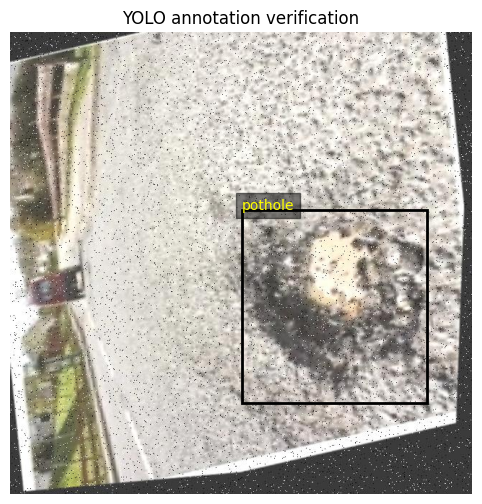

In [25]:
def count_yolo_labels(split):
    label_dir = YOLO_DATA_DIR / split / "labels"
    return sum(1 for p in label_dir.glob("*.txt") if p.stat().st_size > 0)

for split in ["train", "val", "test"]:
    print(f"{split}: images={len(list((YOLO_DATA_DIR/split/'images').glob('*')))}, "
          f"non-empty labels={count_yolo_labels(split)}")

# Visualize one prepared training image and its boxes.
sample_img_path = next((YOLO_DATA_DIR / "train" / "images").glob("*"))
sample_label_path = YOLO_DATA_DIR / "train" / "labels" / f"{sample_img_path.stem}.txt"
sample_img = Image.open(sample_img_path).convert("RGB")
plt.figure(figsize=(8, 6))
plt.imshow(sample_img)
ax = plt.gca()
W, H = sample_img.size
for line in sample_label_path.read_text().splitlines():
    cls_id, xc, yc, bw, bh = map(float, line.split())
    x1 = (xc - bw/2) * W
    y1 = (yc - bh/2) * H
    rect = plt.Rectangle((x1, y1), bw*W, bh*H, fill=False, linewidth=2)
    ax.add_patch(rect)
    ax.text(x1, y1, yolo_class_names[int(cls_id)], color="yellow",
            bbox=dict(facecolor="black", alpha=0.5))
plt.title("YOLO annotation verification")
plt.axis("off")
plt.show()

## 25. Train multiple YOLO models

Three pretrained detectors are compared:
- **YOLOv8n** — nano, fastest and lightweight
- **YOLOv8s** — small, higher capacity
- **YOLO11n** — newer nano architecture

All models use the same train/validation split, image size, batch size and epoch limit for a fair comparison. Training uses early stopping through Ultralytics patience. Adjust `YOLO_EPOCHS` and `YOLO_BATCH` according to your GPU memory.

In [26]:
YOLO_EPOCHS = 50
YOLO_IMAGE_SIZE = 640
YOLO_BATCH = 16 if torch.cuda.is_available() else 4
YOLO_DEVICE = 0 if torch.cuda.is_available() else "cpu"

yolo_model_configs = {
    "YOLOv8n": "yolov8n.pt",
    "YOLOv8s": "yolov8s.pt",
    "YOLO11n": "yolo11n.pt"
}

yolo_trained = {}
yolo_train_times = {}

for display_name, weights_name in yolo_model_configs.items():
    print("\n" + "="*65)
    print("Training", display_name, "using", weights_name)
    print("="*65)

    model = YOLO(weights_name)
    start_time = time.time()

    model.train(
        data=str(yaml_path),
        epochs=YOLO_EPOCHS,
        imgsz=YOLO_IMAGE_SIZE,
        batch=YOLO_BATCH,
        device=YOLO_DEVICE,
        project=str(YOLO_WORK_DIR / "runs"),
        name=display_name.lower().replace("-", "_"),
        pretrained=True,
        optimizer="auto",
        patience=10,
        workers=2,
        seed=SEED,
        plots=True,
        save=True,
        verbose=True
    )

    yolo_train_times[display_name] = time.time() - start_time
    best_weights = Path(model.trainer.save_dir) / "weights" / "best.pt"
    yolo_trained[display_name] = YOLO(str(best_weights))
    print("Best weights:", best_weights)
    print("Training time (minutes):", round(yolo_train_times[display_name] / 60, 2))


Training YOLOv8n using yolov8n.pt
Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/pothole_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n, nbs=64, nms=N

## 26. Evaluate YOLO models on the held-out test set

In [27]:
yolo_results = []

for display_name, model in yolo_trained.items():
    print("\nEvaluating", display_name, "on test split...")
    metrics = model.val(
        data=str(yaml_path),
        split="test",
        imgsz=YOLO_IMAGE_SIZE,
        batch=YOLO_BATCH,
        device=YOLO_DEVICE,
        plots=True,
        project=str(YOLO_WORK_DIR / "evaluation"),
        name=display_name.lower().replace("-", "_")
    )

    box = metrics.box
    yolo_results.append({
        "Model": display_name,
        "Precision": float(box.mp),
        "Recall": float(box.mr),
        "mAP50": float(box.map50),
        "mAP50-95": float(box.map),
        "Training Time (min)": yolo_train_times[display_name] / 60
    })

yolo_comparison_df = pd.DataFrame(yolo_results).sort_values("mAP50-95", ascending=False)
display(yolo_comparison_df.style.format({
    "Precision": "{:.4f}", "Recall": "{:.4f}",
    "mAP50": "{:.4f}", "mAP50-95": "{:.4f}",
    "Training Time (min)": "{:.2f}"
}))


Evaluating YOLOv8n on test split...
Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 24.9±18.2 MB/s, size: 127.2 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/pothole_yolo/dataset/test/labels... 313 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 313/313 382.8it/s 0.8s
val: New cache created: /content/pothole_yolo/dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 20/20 4.2it/s 4.7s
                   all        313        644      0.799      0.691      0.778      0.409
Speed: 1.6ms preprocess, 4.9ms inference, 0.0ms loss, 2.0ms postprocess per image
Results saved to /content/pothole_yolo/evaluation/yolo

,Model,Precision,Recall,mAP50,mAP50-95,Training Time (min)
2,YOLO11n,0.7486,0.7158,0.7846,0.4242,20.77
1,YOLOv8s,0.8318,0.6801,0.7916,0.4116,23.70
0,YOLOv8n,0.7986,0.6910,0.7780,0.4089,20.65


## 27. Plot YOLO model comparison

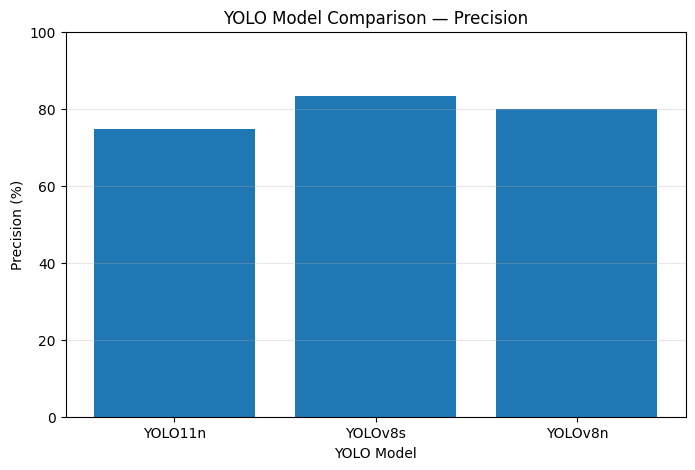

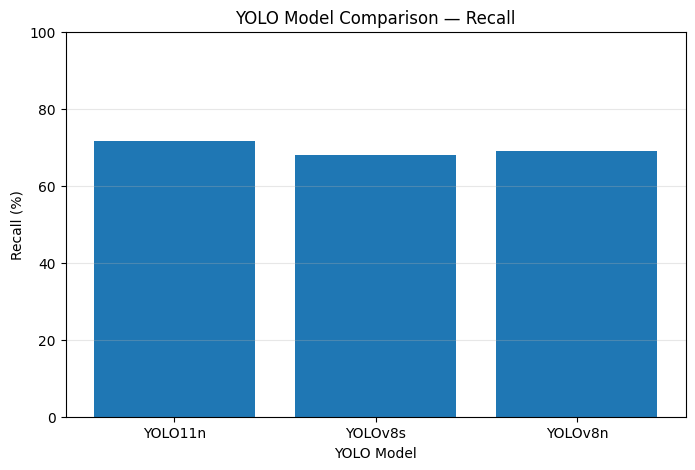

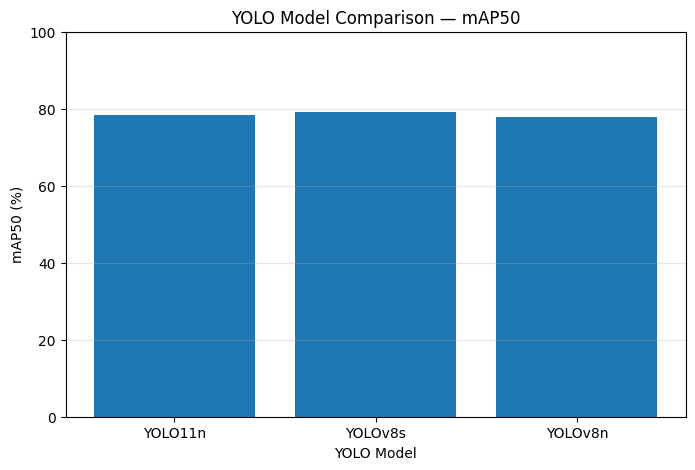

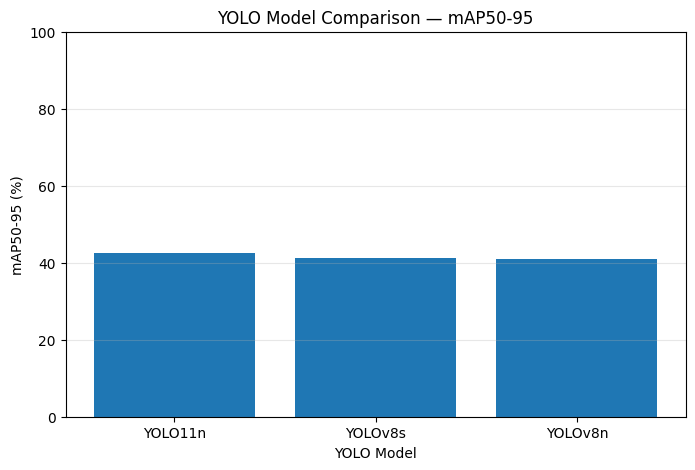

In [28]:
for metric in ["Precision", "Recall", "mAP50", "mAP50-95"]:
    plt.figure(figsize=(8, 5))
    plt.bar(yolo_comparison_df["Model"], yolo_comparison_df[metric] * 100)
    plt.title(f"YOLO Model Comparison — {metric}")
    plt.ylabel(f"{metric} (%)")
    plt.xlabel("YOLO Model")
    plt.ylim(0, 100)
    plt.grid(axis="y", alpha=0.3)
    plt.show()

## 28. Select the best YOLO model and save its weights

In [29]:
best_yolo_name = yolo_comparison_df.iloc[0]["Model"]
best_yolo = yolo_trained[best_yolo_name]
best_yolo_path = YOLO_WORK_DIR / "best_pothole_yolo.pt"
shutil.copy2(best_yolo.ckpt_path, best_yolo_path)

print("Best YOLO model:", best_yolo_name)
print("Best model weights:", best_yolo_path)

Best YOLO model: YOLO11n
Best model weights: /content/pothole_yolo/best_pothole_yolo.pt


## 29. Test YOLO detection on a new road image

Saving Screenshot 2026-11-04 171028.png to Screenshot 2026-11-04 171028.png

image 1/1 /content/Screenshot 2026-11-04 171028.png: 416x640 3 potholes, 48.8ms
Speed: 1.5ms preprocess, 48.8ms inference, 1.9ms postprocess per image at shape (1, 3, 416, 640)
Results saved to /content/runs/detect/predict


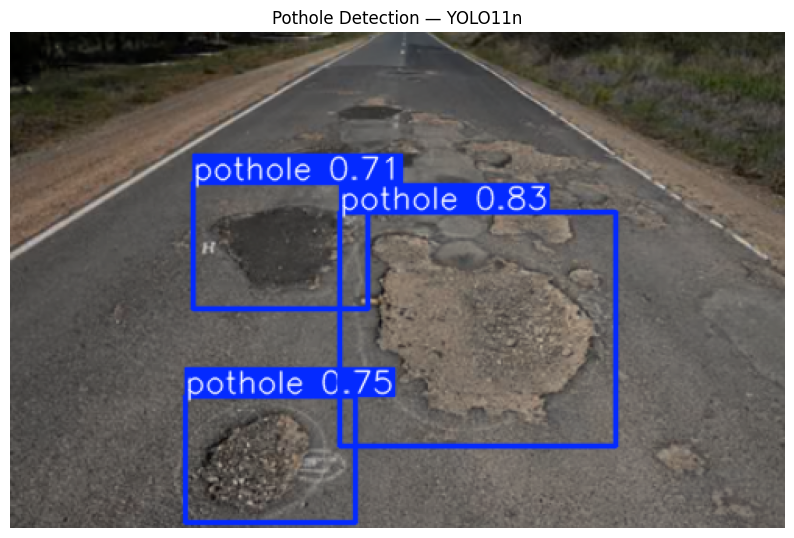

Detected potholes: 3


In [33]:
from google.colab import files

uploaded_yolo = files.upload()
yolo_image_path = next(iter(uploaded_yolo))

prediction = best_yolo.predict(
    source=yolo_image_path,
    imgsz=YOLO_IMAGE_SIZE,
    conf=0.25,
    save=True
)

# Display the annotated detection image.
annotated = prediction[0].plot()
plt.figure(figsize=(10, 7))
plt.imshow(annotated[:, :, ::-1])
plt.title(f"Pothole Detection — {best_yolo_name}")
plt.axis("off")
plt.show()

print("Detected potholes:", len(prediction[0].boxes))

## 30. Final YOLO results summary

Use the measured test-set results from the comparison table in your report. Do not copy example accuracy values from other projects: YOLO detection is evaluated using precision, recall and mAP rather than ordinary image-classification accuracy.

In [34]:
print("YOLO OBJECT DETECTION RESULTS")
print("=" * 55)
display(yolo_comparison_df)
print("Best YOLO model:", best_yolo_name)
print("Saved weights:", best_yolo_path)

YOLO OBJECT DETECTION RESULTS


,Model,Precision,Recall,mAP50,mAP50-95,Training Time (min)
2,YOLO11n,0.748604,0.715839,0.784639,0.424183,20.767001
1,YOLOv8s,0.831771,0.680124,0.791620,0.411624,23.703521
0,YOLOv8n,0.798579,0.690994,0.777989,0.408851,20.645941


Best YOLO model: YOLO11n
Saved weights: /content/pothole_yolo/best_pothole_yolo.pt
